In [53]:
import json

with open(".test/config.json") as json_file:
    config = json.load(json_file)  
    model_name = config['model']['name']
    model_params = config['model'].get('params', {})
    training_params = config['training']
    data_params = config['data']

with open('.test/class_mapping.json', 'r') as f:
    idx_to_class = json.load(f)
    
num_classes = len(idx_to_class)

In [54]:
import torch
from torch.utils.data import DataLoader, TensorDataset
import torchvision.transforms.v2 as transforms
import torchvision.datasets as datasets

In [55]:
transform = transforms.Compose([
    transforms.Resize(data_params['image_size']),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=data_params['mean'], std=data_params['std']),
])

In [56]:
# dataset = datasets.ImageFolder(root='data/raw', transform=transform)
# dataloader = DataLoader(dataset, batch_size=training_params['batch_size'], shuffle=False, num_workers=training_params['num_workers'], pin_memory=True)

In [57]:
import src.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
Model = getattr(models, model_name)
model = Model(num_classes, **model_params).to(device)

model.eval()
model.load_state_dict(torch.load(f".test/models/{model_name}.pt", map_location=device))
model_name

'ResNet34Model'

In [58]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

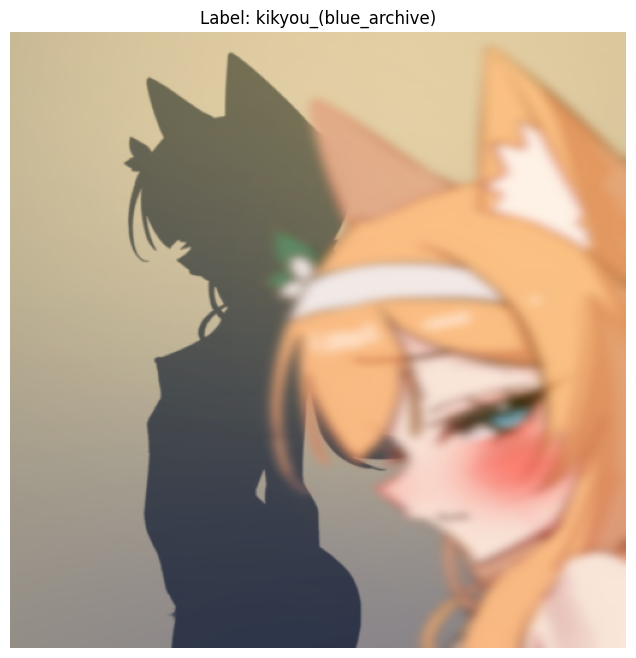

In [110]:
# img, label = da
# taset[2997]

img = Image.open("/home/gjmrem/Downloads/.test/__mari_blue_archive_drawn_by_agnamore__12295460bbae0b16c006d5da16872dcc.png").convert("RGB")
img = transform(img)
label = 91

mean = np.array(data_params["mean"])
std = np.array(data_params["std"])
img_disp = img.permute(1, 2, 0).cpu().numpy() * std + mean
img_disp = np.clip(img_disp, 0, 1)

plt.figure(figsize=(8, 8))
plt.imshow(img_disp)
plt.title(f"Label: {idx_to_class[str(label)]}")
plt.axis('off')
plt.show()

-27.862875 7.4394093


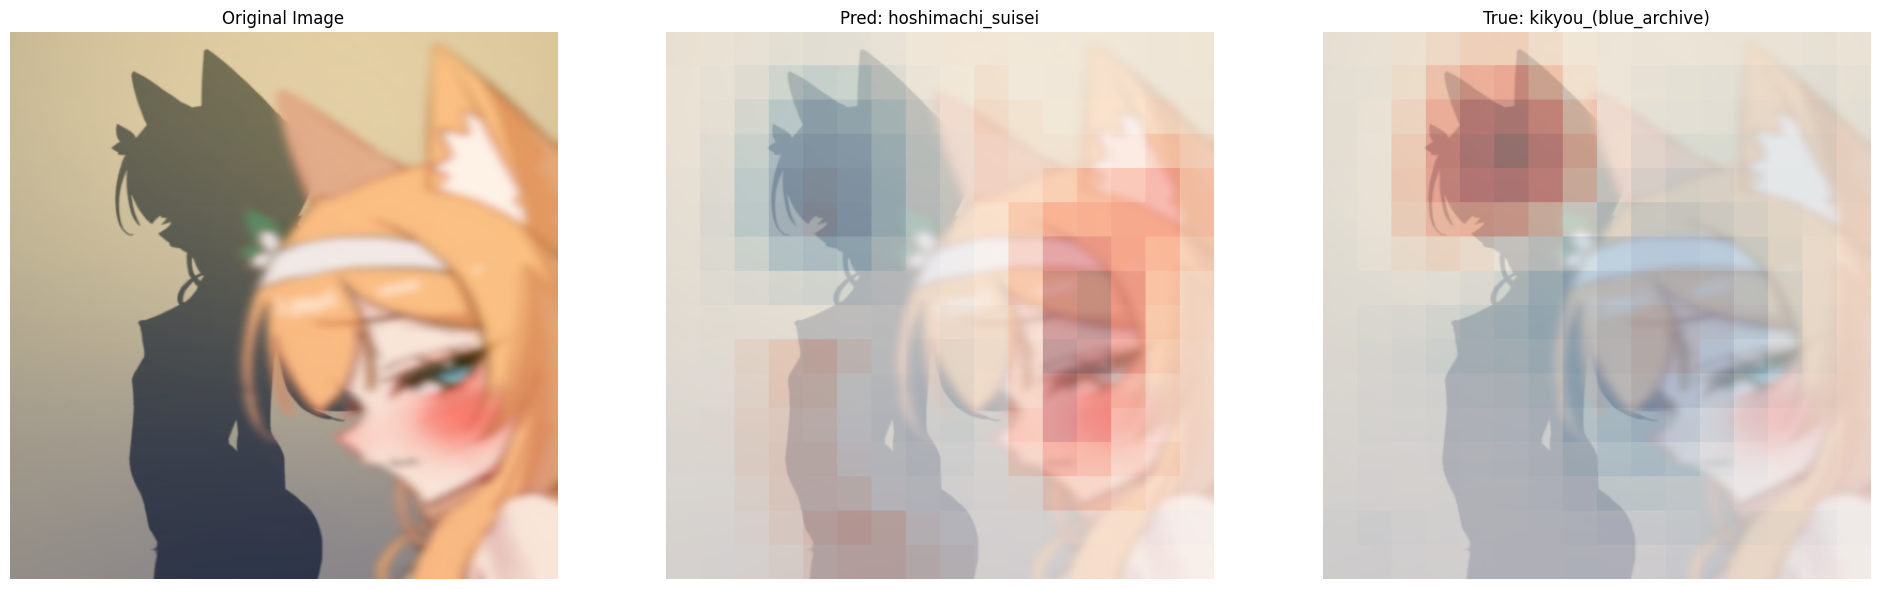

In [111]:
# 1. Load your model and set to eval mode
model.eval()

# 2. Load and preprocess your image
input_tensor = img.unsqueeze(0).to(device)

# 3. Register a hook to get the feature maps from the last conv layer
features = []
def hook_fn(module, input, output):
    features.append(output.detach().cpu().numpy())

# For ResNet, the last conv layer is usually model.resnet.layer4[-1]
# Adjust if your model structure is different
handle = model.resnet.layer4[-1].register_forward_hook(hook_fn)

# 4. Forward pass
with torch.no_grad():
    output = model(input_tensor)
    pred_class = output.argmax(dim=1).item()

# 5. Get the weights of the final fc layer
params = list(model.resnet.fc.parameters())

# weight_softmax = torch.nn.functional.softmax(params[0], dim=0).detach().cpu().numpy()
weight_softmax = params[0].detach().cpu().numpy()

# 6. Compute the CAM
feature_maps = features[0][0]  # shape: [C, H, W]
cam = weight_softmax[pred_class].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam = cam.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
cam_max = np.max(np.abs(cam))
cam_neg = np.minimum(cam, 0)
cam_pos = np.maximum(cam, 0)

print(cam.min(), cam.max())
# cam = (cam / (2*cam_max)) + (1/2)
# cam = cam - cam.min()
# cam = cam / cam.max()
cam = cam_pos / cam_max
cam_neg = - cam_neg / cam_max
      
cam = Image.fromarray((cam *255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
# cam_pos = Image.fromarray((cam_pos * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BILINEAR)
cam_neg = Image.fromarray((cam_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

cam_true = weight_softmax[label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_true = cam_true.reshape(feature_maps.shape[1], feature_maps.shape[2])

cam_true_max = np.max(np.abs(cam_true))
cam_true_neg = np.minimum(cam_true, 0)
cam_true = np.maximum(cam_true, 0)

cam_true = cam_true / cam_true_max
cam_true_neg = - cam_true_neg / cam_true_max

cam_true = Image.fromarray((cam_true * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_true_neg = Image.fromarray((cam_true_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)


plt.figure(figsize=(24,8))

plt.subplot(1,3,1)
# plt.imshow(img.permute(1, 2, 0))
plt.imshow(img_disp)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(img_disp)
plt.imshow(cam, cmap='Reds', alpha=0.5)
plt.imshow(cam_neg, cmap='Blues', alpha=0.3)
plt.title(f"Pred: {idx_to_class[str(pred_class)]}")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}")
plt.axis('off')

plt.show()

# Don't forget to remove the hook
handle.remove()

In [112]:
probabilities = torch.nn.functional.softmax(output, dim=1).detach().cpu().numpy()[0]
print(f"Top 3 predictions:")
top3_indices = np.argsort(probabilities)[-3:][::-1]
for idx in top3_indices:
    print(f"{idx_to_class[str(idx)]}: {probabilities[idx]:.4f}")

Top 3 predictions:
hoshimachi_suisei: 0.3573
mari_(blue_archive): 0.2441
ju_fufu: 0.0969


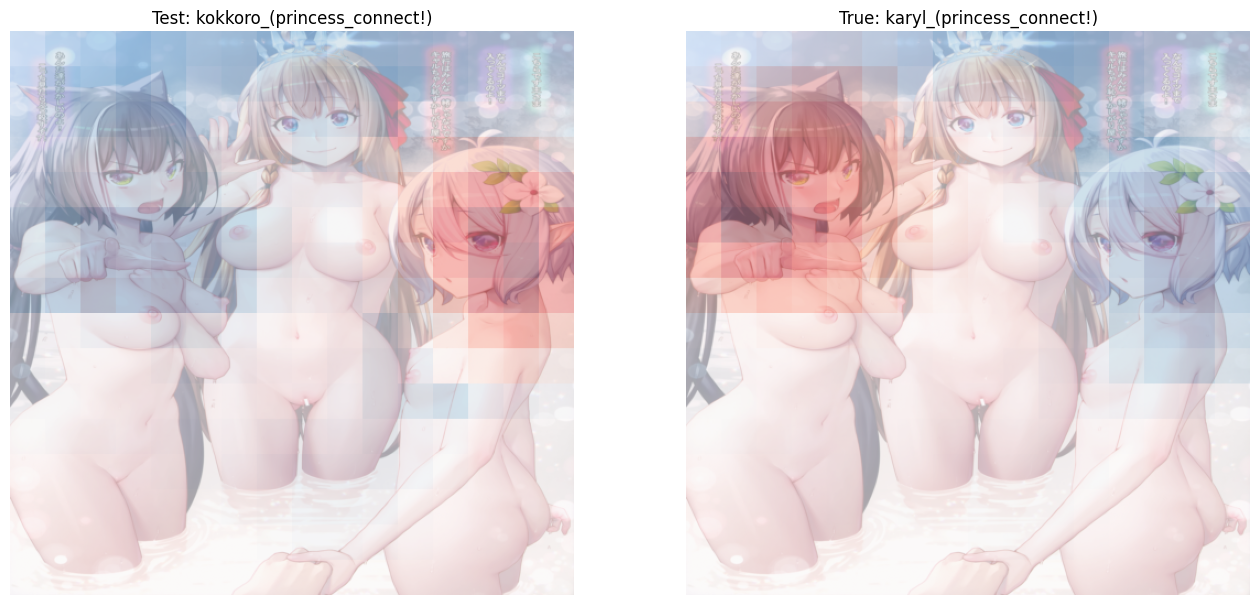

In [73]:
test_label = 77
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
# cam_test_neg = np.minimum(cam_test, 0)
# cam_test = np.maximum(cam_test, 0)

cam_test_max = np.max(np.abs(cam_test))
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test_max
cam_test_neg = - cam_test_neg / cam_test_max

# cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
# cam_test_neg = - cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='Reds', alpha=0.5)
plt.imshow(cam_test_neg, cmap='Blues', alpha=0.3)
plt.title(f"Test: {idx_to_class[str(test_label)]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}")
plt.axis('off')


plt.show()

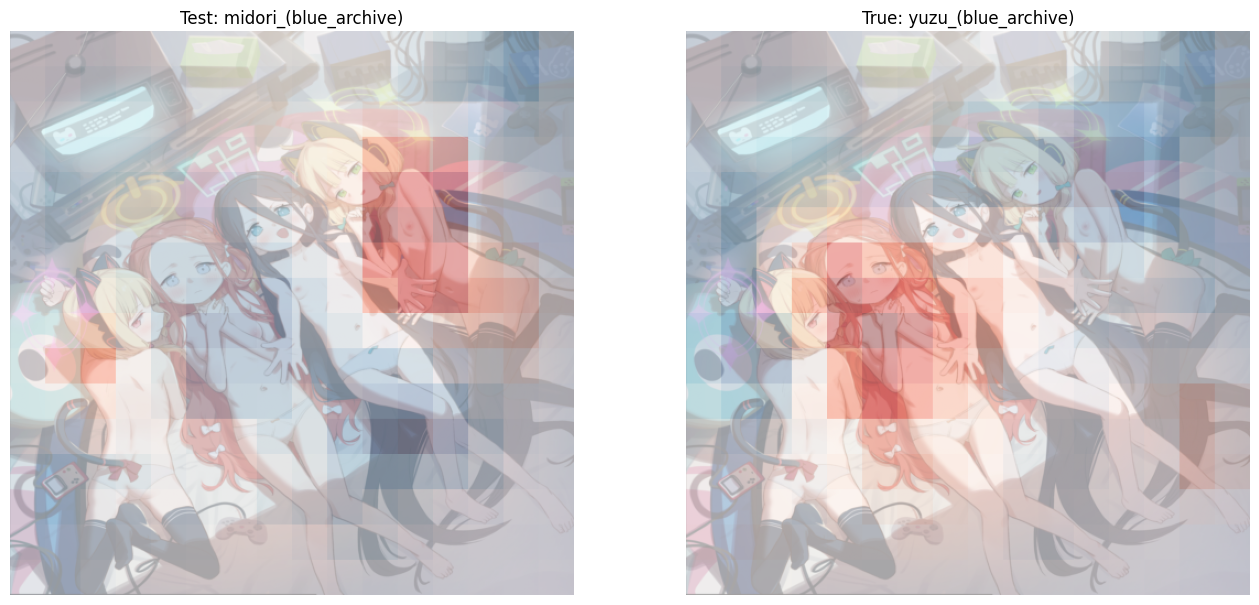

In [92]:
test_label = 88
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
# cam_test_neg = np.minimum(cam_test, 0)
# cam_test = np.maximum(cam_test, 0)

cam_test_max = np.max(np.abs(cam_test))
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test_max
cam_test_neg = - cam_test_neg / cam_test_max

# cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
# cam_test_neg = - cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='Reds', alpha=0.5)
plt.imshow(cam_test_neg, cmap='Blues', alpha=0.3)
plt.title(f"Test: {idx_to_class[str(test_label)]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}")
plt.axis('off')


plt.show()

In [258]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

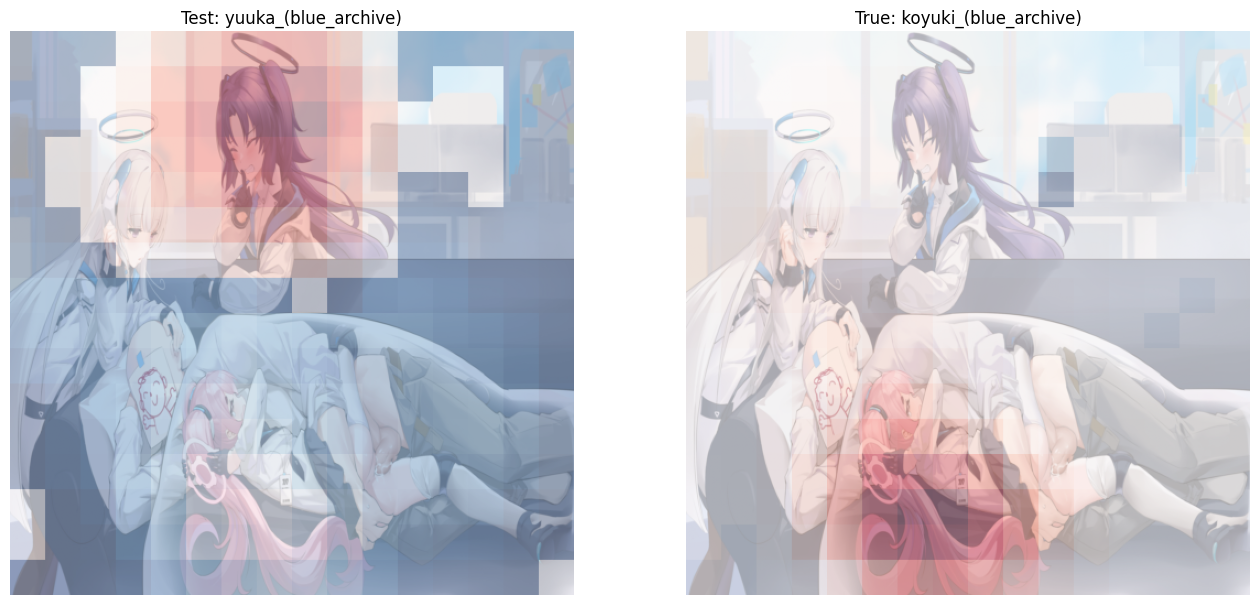

In [15]:
test_label = 174
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
cam_test_neg = - cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='Reds', alpha=0.5)
plt.imshow(cam_test_neg, cmap='Blues', alpha=0.3)
plt.title(f"Test: {idx_to_class[str(test_label)]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}")
plt.axis('off')


plt.show()

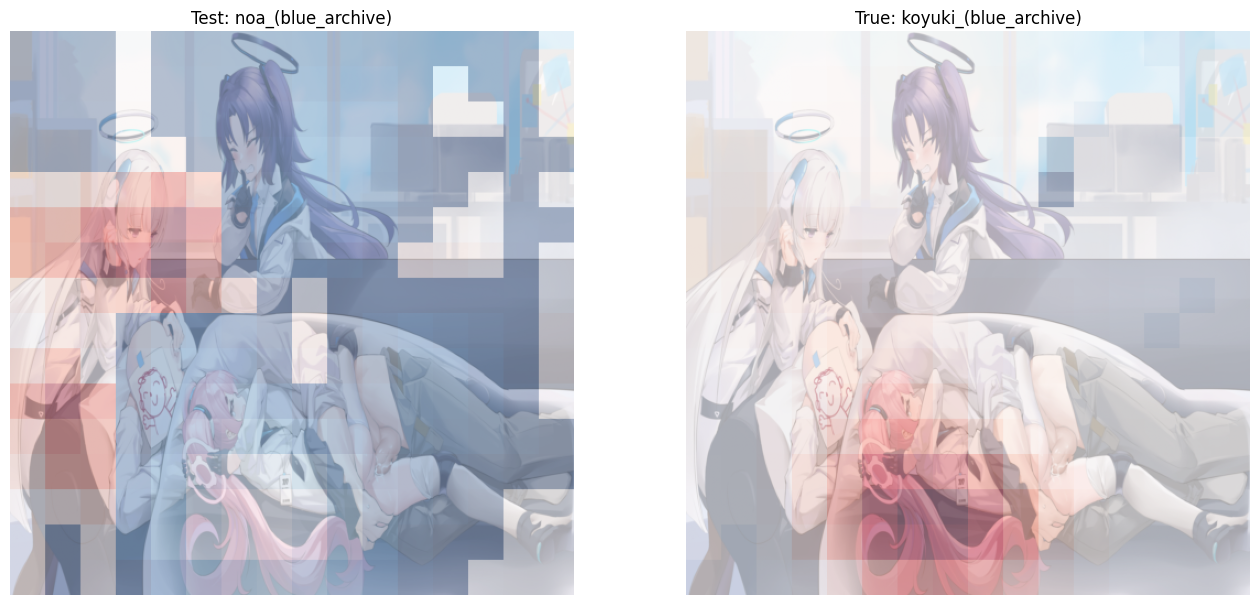

In [16]:
test_label = 117
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
cam_test_neg = - cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='Reds', alpha=0.5)
plt.imshow(cam_test_neg, cmap='Blues', alpha=0.3)
plt.title(f"Test: {idx_to_class[str(test_label)]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}")
plt.axis('off')


plt.show()

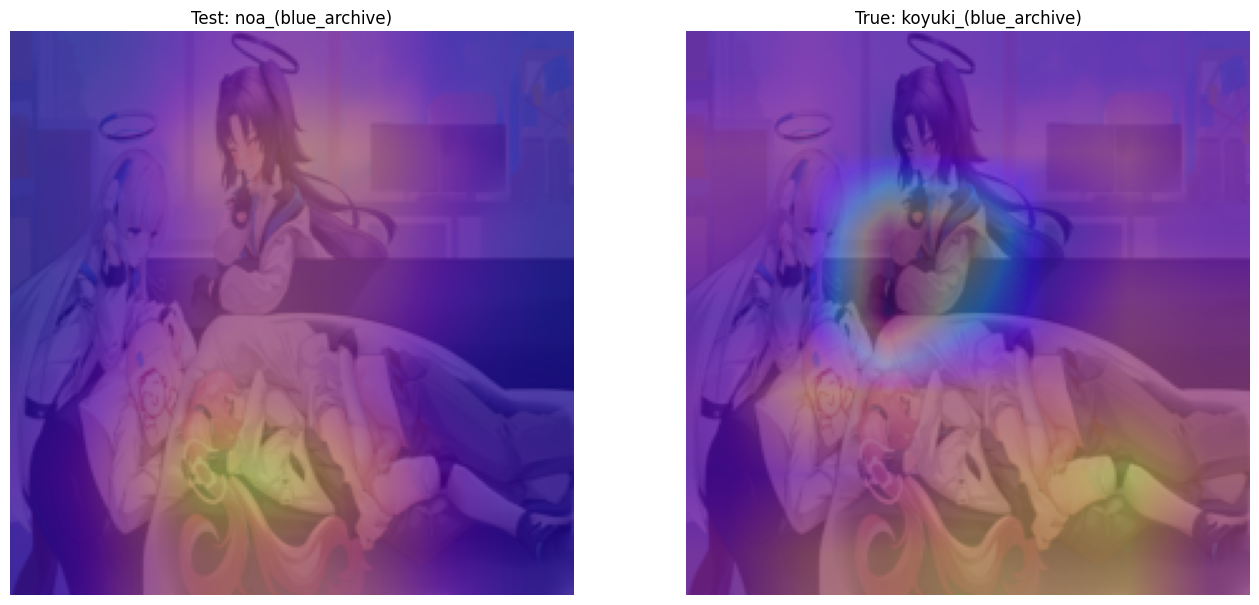

In [ ]:
test_label = 149
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
cam_test_neg = cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BILINEAR)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BILINEAR)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='jet', alpha=0.5)
plt.imshow(cam_test_neg, cmap='plasma', alpha=0.5)
plt.title(f"Test: {dataset.classes[test_label]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='jet', alpha=0.5)
plt.imshow(cam_true_neg, cmap='plasma', alpha=0.5)
plt.title(f"True: {dataset.classes[label]}")
plt.axis('off')


plt.show()

In [ ]:
from tqdm.autonotebook import tqdm
# Display the confusion matrix
predictions = []
y_true = []

model.eval()
with torch.no_grad():
    for X, y in tqdm(dataloader):
        X, y = X.to(device), y.to(device)
        
        output = model(X)
        pred = output.argmax(dim=1)
        
        y_true.append(y.cpu())
        predictions.append(pred.cpu())

predictions = torch.cat(predictions)
y_true = torch.cat(y_true)

 11%|█▏        | 28/246 [05:15<37:04, 10.20s/it] /home/gjmrem/dev/projects/anime-classifier/.venv/lib/python3.10/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 4 bytes but only got 0. 
  warnings.warn(str(msg))
100%|██████████| 246/246 [56:36<00:00, 13.81s/it]


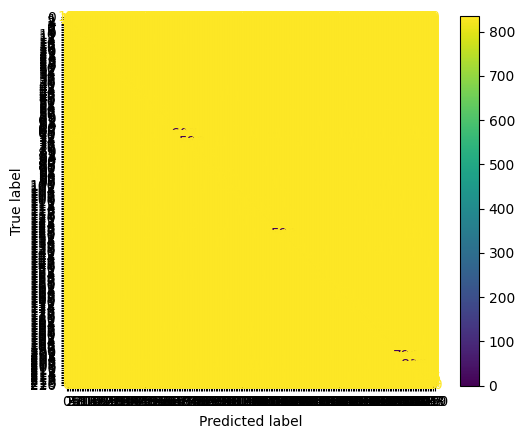

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true.numpy(), predictions.numpy())
ConfusionMatrixDisplay(cm).plot()

In [ ]:
predictions.numpy()

array([  0,   0,   0, ..., 220, 220, 220], shape=(15691,))

<Figure size 1600x1600 with 0 Axes>

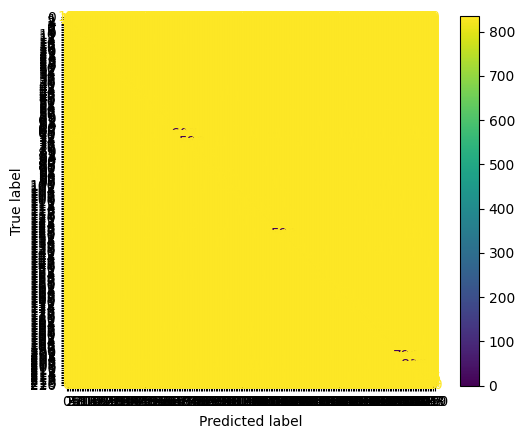

In [ ]:
plt.figure(figsize=(16,16))
ConfusionMatrixDisplay(cm).plot()

In [ ]:
import mlflow

model = mlflow.pyfunc.load_model("models:/ResNet18Model/7")

In [ ]:
from torchvision.models import swin_t
model = swin_t()
model

SwinTransformer(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): Permute()
      (2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
    )
    (1): Sequential(
      (0): SwinTransformerBlock(
        (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
        (attn): ShiftedWindowAttention(
          (qkv): Linear(in_features=96, out_features=288, bias=True)
          (proj): Linear(in_features=96, out_features=96, bias=True)
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
        (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
        (mlp): MLP(
          (0): Linear(in_features=96, out_features=384, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=384, out_features=96, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (1): SwinTransformerBlock(
       